# Microclimas de la Región de Coquimbo: costa vs. valle (2024–2025)

¿Cuánto cambia el clima en 80 km, desde la costa de Tongoy hasta el valle de Elqui? Este análisis compara
temperatura, amplitud térmica, lluvia, radiación y humedad en 8 localidades de la región durante dos años completos.

**Origen.** Es la versión ampliada del Laboratorio 1 de Machine Learning (2025), que hacía *web scraping* de CEAZA
y consultaba la API de OpenWeather para 5 localidades entre enero y agosto de 2025 (notebook original en
`originales/`). Aquí se usa la API histórica de **Open-Meteo** (gratuita, sin API key) para tener 2 años y 8 puntos.

In [1]:
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style="whitegrid")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
DATA = Path("../data/clima_coquimbo_2024_2025.csv")

## 1. Datos

La celda siguiente descarga los datos si el CSV no existe (en Colab funciona tal cual). Variables diarias:
temperatura máxima, mínima y media (°C), precipitación (mm), viento máximo (km/h), radiación solar (MJ/m²) y
humedad relativa media (%).

In [2]:
LOCALIDADES = {
    "Coquimbo": (-29.9533, -71.3436), "La Serena": (-29.9027, -71.2519),
    "Tongoy-Guanaqueros": (-30.2567, -71.4950), "Punta de Choros": (-29.2453, -71.4636),
    "La Higuera": (-29.5097, -71.2611), "Andacollo": (-30.2316, -71.0838),
    "Vicuña": (-30.0319, -70.7081), "Paihuano (Gabriela Mistral)": (-30.0283, -70.5181),
}

def descargar(path=DATA, start="2024-01-01", end="2025-12-31"):
    vars_ = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "precipitation_sum",
             "wind_speed_10m_max", "shortwave_radiation_sum", "relative_humidity_2m_mean"]
    nombres = ["tmax", "tmin", "tmean", "precip_mm", "viento_max_kmh", "radiacion_MJm2", "hr_media"]
    frames = []
    for loc, (la, lo) in LOCALIDADES.items():
        url = (f"https://archive-api.open-meteo.com/v1/archive?latitude={la}&longitude={lo}"
               f"&start_date={start}&end_date={end}&daily={','.join(vars_)}&timezone=America%2FSantiago")
        js = json.load(urllib.request.urlopen(url, timeout=60))
        d = pd.DataFrame(js["daily"]).rename(columns=dict(zip(vars_, nombres))).rename(columns={"time": "fecha"})
        d.insert(0, "localidad", loc); d.insert(1, "lat", js["latitude"]); d.insert(2, "lon", js["longitude"])
        d.insert(3, "elevacion_m", js["elevation"]); frames.append(d)
    pd.concat(frames).to_csv(path, index=False)

if not DATA.exists():
    descargar()
df = pd.read_csv(DATA, parse_dates=["fecha"])
df["amplitud"] = df.tmax - df.tmin
df["mes"] = df.fecha.dt.month
df["anio"] = df.fecha.dt.year
ZONA = {"Coquimbo": "Costa", "La Serena": "Costa", "Tongoy-Guanaqueros": "Costa", "Punta de Choros": "Costa",
        "La Higuera": "Interior", "Andacollo": "Interior", "Vicuña": "Valle de Elqui",
        "Paihuano (Gabriela Mistral)": "Valle de Elqui"}
df["zona"] = df.localidad.map(ZONA)
print(df.shape, df.fecha.min().date(), "→", df.fecha.max().date())
df.head()

(5848, 16) 2024-01-01 → 2025-12-31


,localidad,lat,lon,elevacion_m,fecha,tmax,tmin,tmean,precip_mm,viento_max_kmh,radiacion_MJm2,hr_media,amplitud,mes,anio,zona
0,Coquimbo,-29.982,-71.329,91,2024-01-01,21.6,14.5,17.9,0.0,22.1,31.90,71,7.1,1,2024,Costa
1,Coquimbo,-29.982,-71.329,91,2024-01-02,20.6,14.2,17.8,0.0,17.9,30.25,75,6.4,1,2024,Costa
2,Coquimbo,-29.982,-71.329,91,2024-01-03,20.4,15.1,17.6,0.4,16.9,27.65,76,5.3,1,2024,Costa
3,Coquimbo,-29.982,-71.329,91,2024-01-04,20.6,14.8,17.4,0.3,16.5,26.55,80,5.8,1,2024,Costa
4,Coquimbo,-29.982,-71.329,91,2024-01-05,20.1,15.0,17.4,0.3,16.9,24.43,76,5.1,1,2024,Costa


## 2. Resumen por localidad

In [3]:
orden = df.groupby("localidad").tmean.mean().sort_values().index
resumen = df.groupby("localidad").agg(
    zona=("zona", "first"), elevacion_m=("elevacion_m", "first"),
    t_media=("tmean", "mean"), t_min_abs=("tmin", "min"), t_max_abs=("tmax", "max"),
    amplitud_media=("amplitud", "mean"), lluvia_anual_mm=("precip_mm", lambda s: s.sum() / 2),
    radiacion_media=("radiacion_MJm2", "mean"), humedad_media=("hr_media", "mean"),
).loc[orden].round(1)
resumen.to_csv("../data/resumen_localidades.csv")
resumen

,zona,elevacion_m,t_media,t_min_abs,t_max_abs,amplitud_media,lluvia_anual_mm,radiacion_media,humedad_media
localidad,,,,,,,,,
La Higuera,Interior,635,13.4,1.1,25.1,6.8,85.4,21.6,74.9
Coquimbo,Costa,91,14.3,3.6,24.0,7.2,154.8,20.2,81.6
Punta de Choros,Costa,14,14.6,6.5,23.5,5.3,143.0,19.1,82.5
La Serena,Costa,26,15.0,3.7,26.0,8.6,163.5,20.5,78.2
Tongoy-Guanaqueros,Costa,6,15.2,3.5,30.5,9.2,166.6,20.5,74.2
Andacollo,Interior,1014,16.2,0.5,32.1,9.3,182.4,22.2,57.8
Vicuña,Valle de Elqui,620,19.2,2.7,36.5,10.6,129.4,22.2,53.0
Paihuano (Gabriela Mistral),Valle de Elqui,966,19.7,-8.3,35.1,10.4,216.7,23.3,40.8


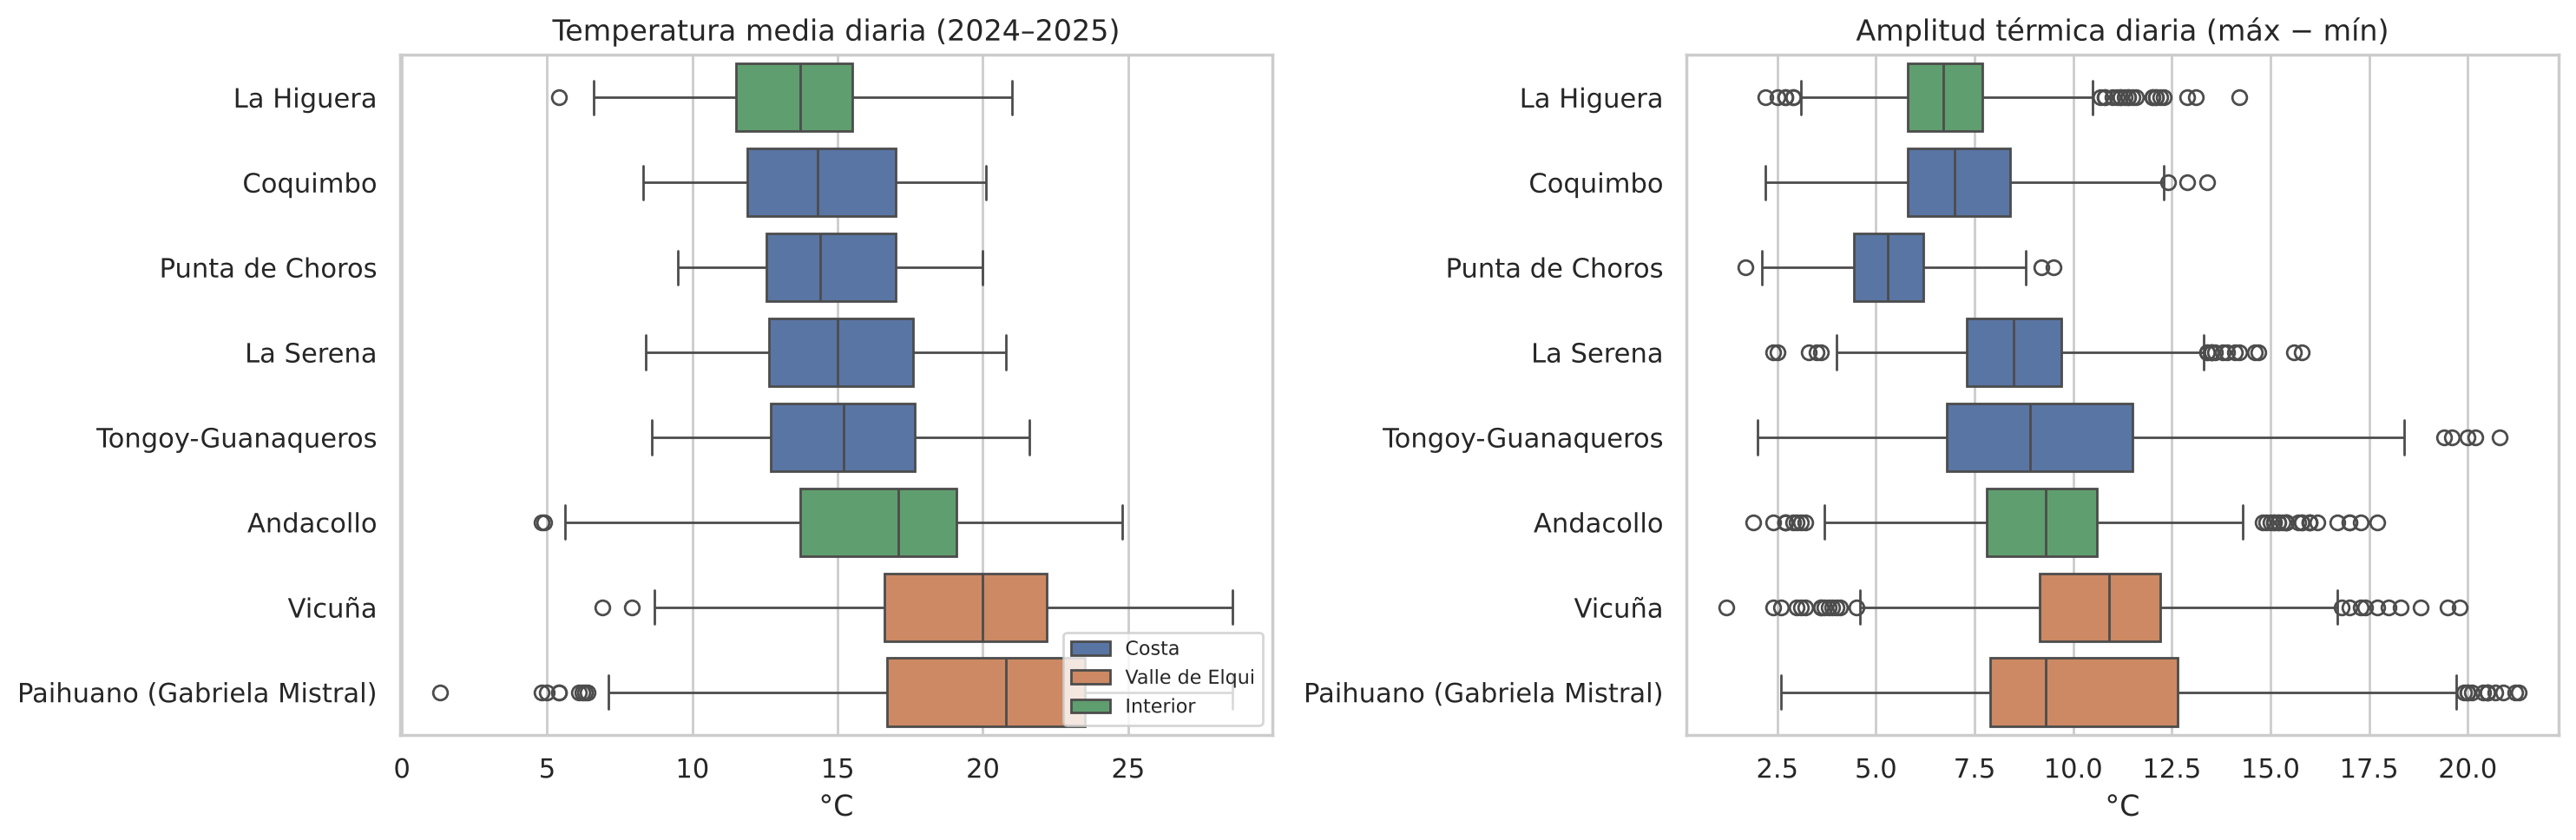

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="tmean", y="localidad", order=orden, hue="zona", dodge=False, ax=axes[0])
axes[0].set_title("Temperatura media diaria (2024–2025)"); axes[0].set_xlabel("°C"); axes[0].set_ylabel(""); axes[0].legend(loc="lower right", fontsize=8)
sns.boxplot(data=df, x="amplitud", y="localidad", order=orden, hue="zona", dodge=False, ax=axes[1], legend=False)
axes[1].set_title("Amplitud térmica diaria (máx − mín)"); axes[1].set_xlabel("°C"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "boxplots.png", dpi=120); plt.show()

## 3. Ciclo anual

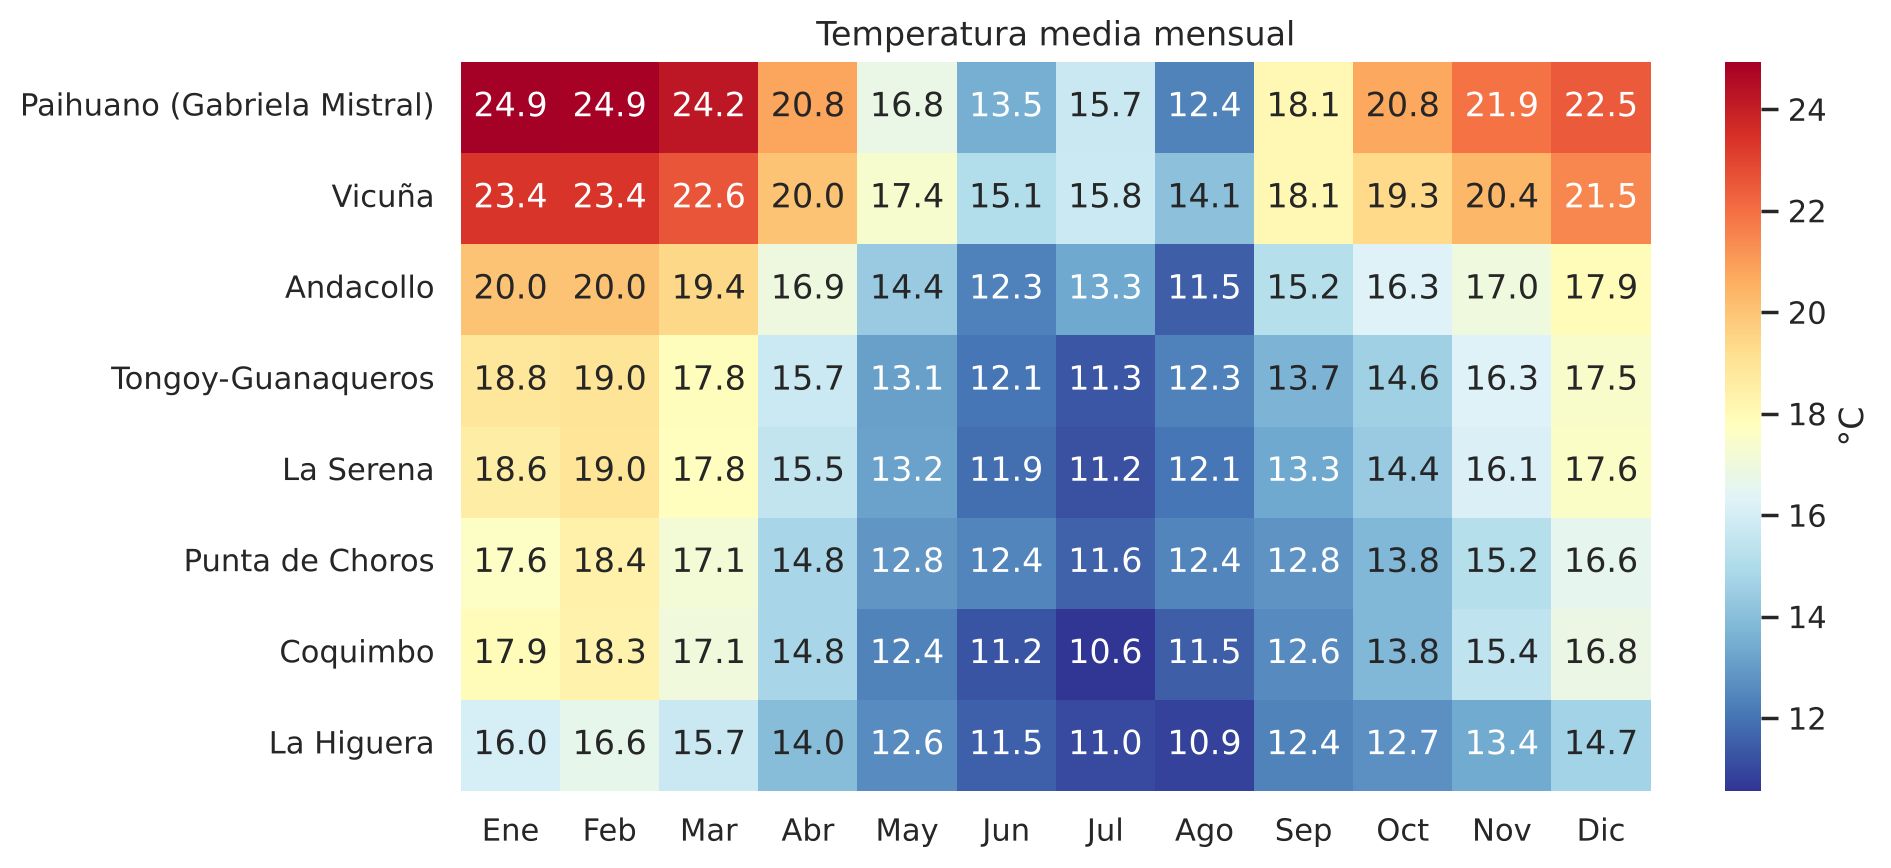

In [5]:
mens = df.groupby(["localidad", "mes"]).tmean.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(mens.loc[orden[::-1]], annot=True, fmt=".1f", cmap="RdYlBu_r", ax=ax, cbar_kws={"label": "°C"})
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Temperatura media mensual"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "heatmap_mensual.png", dpi=120); plt.show()

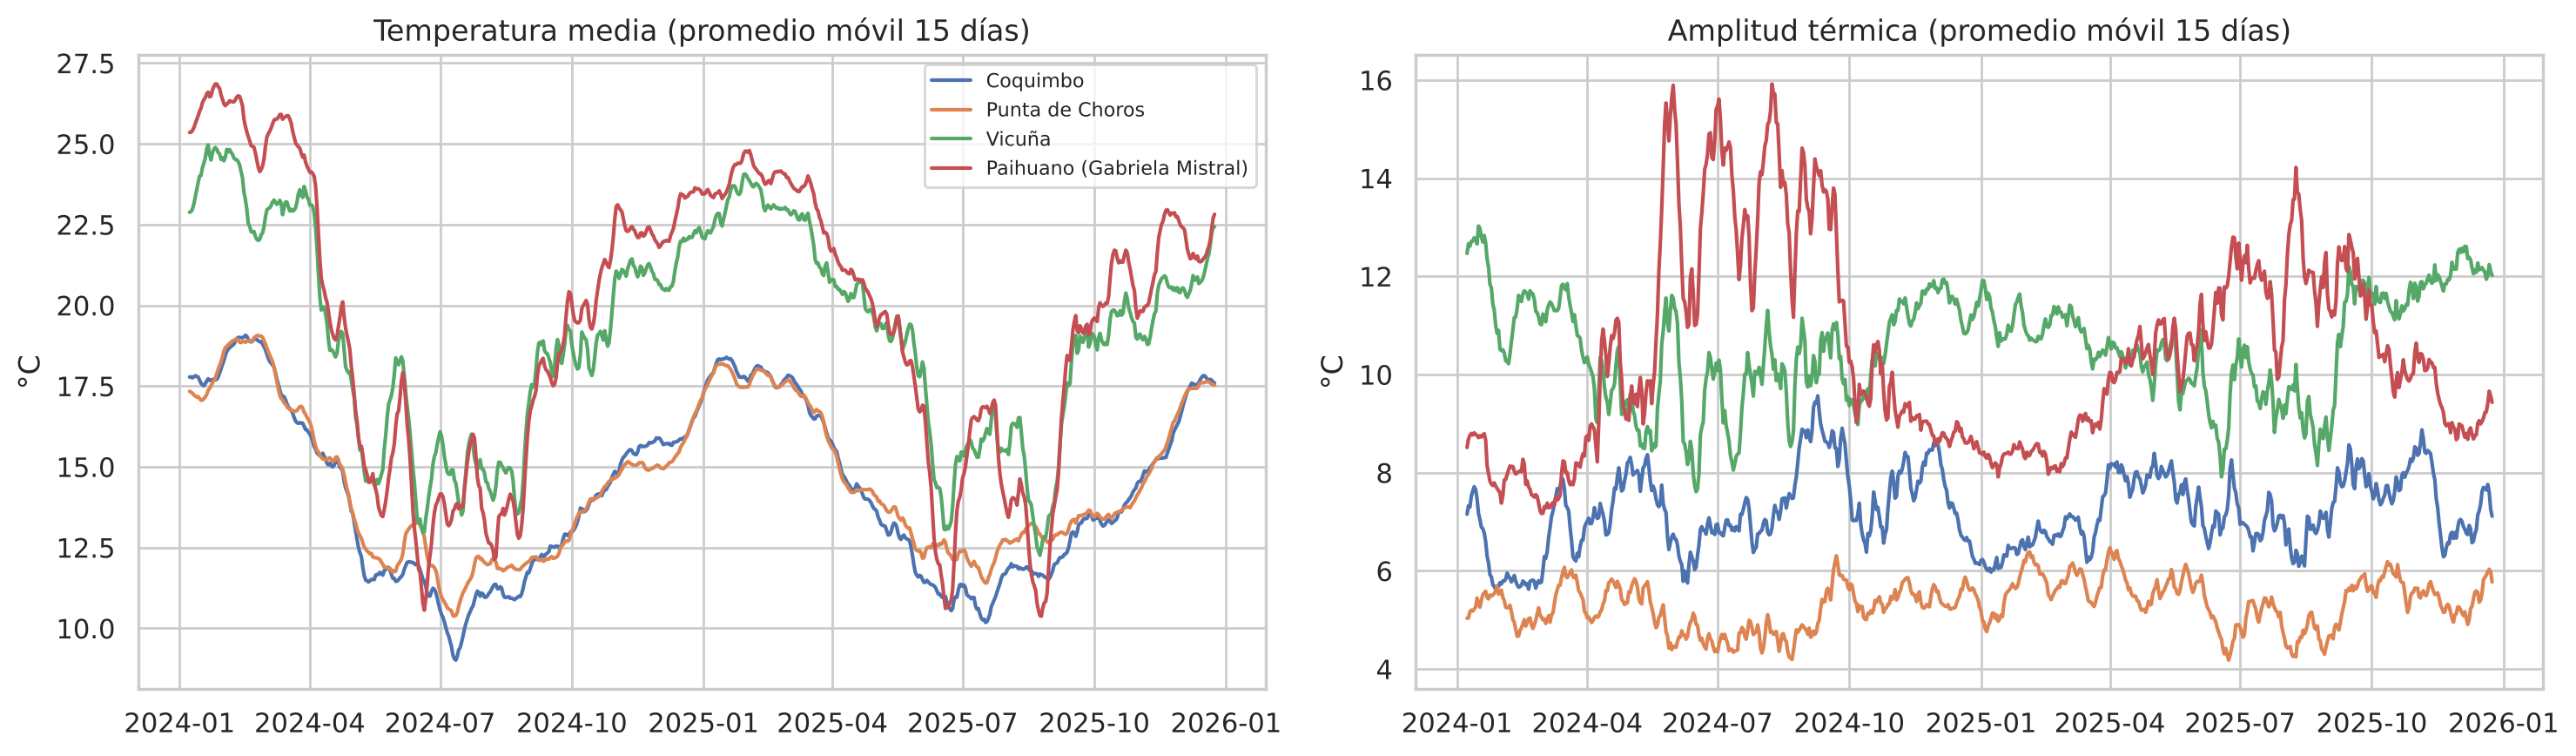

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for loc in ["Coquimbo", "Punta de Choros", "Vicuña", "Paihuano (Gabriela Mistral)"]:
    d = df[df.localidad == loc].set_index("fecha")
    axes[0].plot(d.tmean.rolling(15, center=True).mean(), label=loc)
    axes[1].plot(d.amplitud.rolling(15, center=True).mean(), label=loc)
axes[0].set_title("Temperatura media (promedio móvil 15 días)"); axes[0].set_ylabel("°C")
axes[1].set_title("Amplitud térmica (promedio móvil 15 días)"); axes[1].set_ylabel("°C")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "series.png", dpi=120); plt.show()

## 4. ¿Qué explica las diferencias? Elevación y distancia a la costa

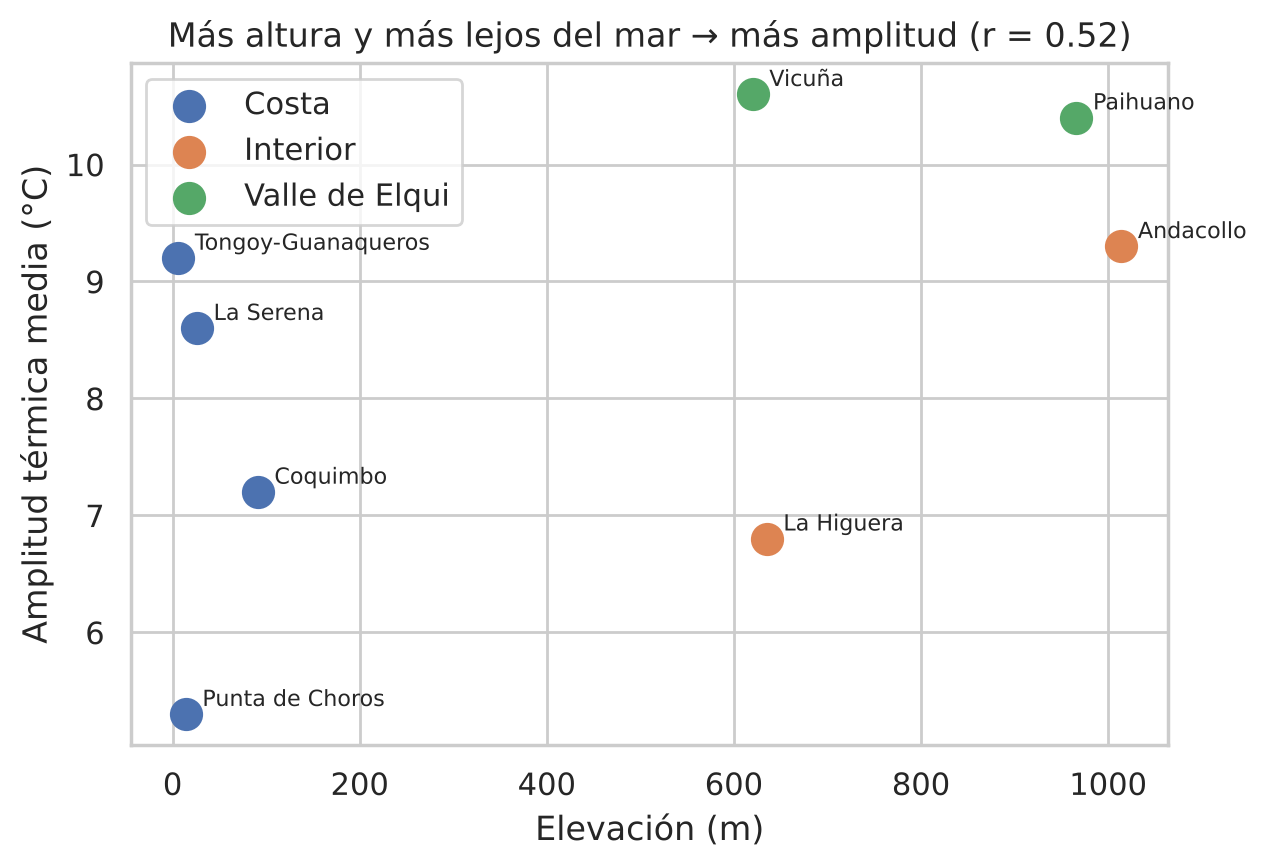

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for z, g in resumen.groupby("zona"):
    ax.scatter(g.elevacion_m, g.amplitud_media, s=120, label=z)
for loc, r in resumen.iterrows():
    ax.annotate(loc.split(" (")[0], (r.elevacion_m, r.amplitud_media), xytext=(6, 3), textcoords="offset points", fontsize=8)
r = np.corrcoef(resumen.elevacion_m, resumen.amplitud_media)[0, 1]
ax.set_xlabel("Elevación (m)"); ax.set_ylabel("Amplitud térmica media (°C)")
ax.set_title(f"Más altura y más lejos del mar → más amplitud (r = {r:.2f})"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "elevacion_amplitud.png", dpi=120); plt.show()

## 5. Lluvia: pocos días, mucho impacto

In [8]:
lluvia = df[df.precip_mm >= 10].groupby(["fecha"]).agg(localidades=("localidad", "count"),
                                                        max_mm=("precip_mm", "max")).sort_values("max_mm", ascending=False)
dias_lluvia = df.assign(llueve=df.precip_mm >= 1).groupby("localidad").llueve.sum() / 2
print("Días al año con lluvia ≥ 1 mm:", dias_lluvia.round(0).astype(int).to_dict())
lluvia.head(8)

Días al año con lluvia ≥ 1 mm: {'Andacollo': 14, 'Coquimbo': 14, 'La Higuera': 12, 'La Serena': 16, 'Paihuano (Gabriela Mistral)': 17, 'Punta de Choros': 29, 'Tongoy-Guanaqueros': 18, 'Vicuña': 12}


,localidades,max_mm
fecha,,
2024-06-14,8,57.3
2024-08-02,8,51.7
2024-06-13,5,46.0
2025-08-01,8,42.8
2025-06-16,7,32.1
2024-04-14,2,31.6
2024-04-13,1,30.3
2024-05-22,2,29.6


## 6. Agrupación de localidades por clima (clustering)

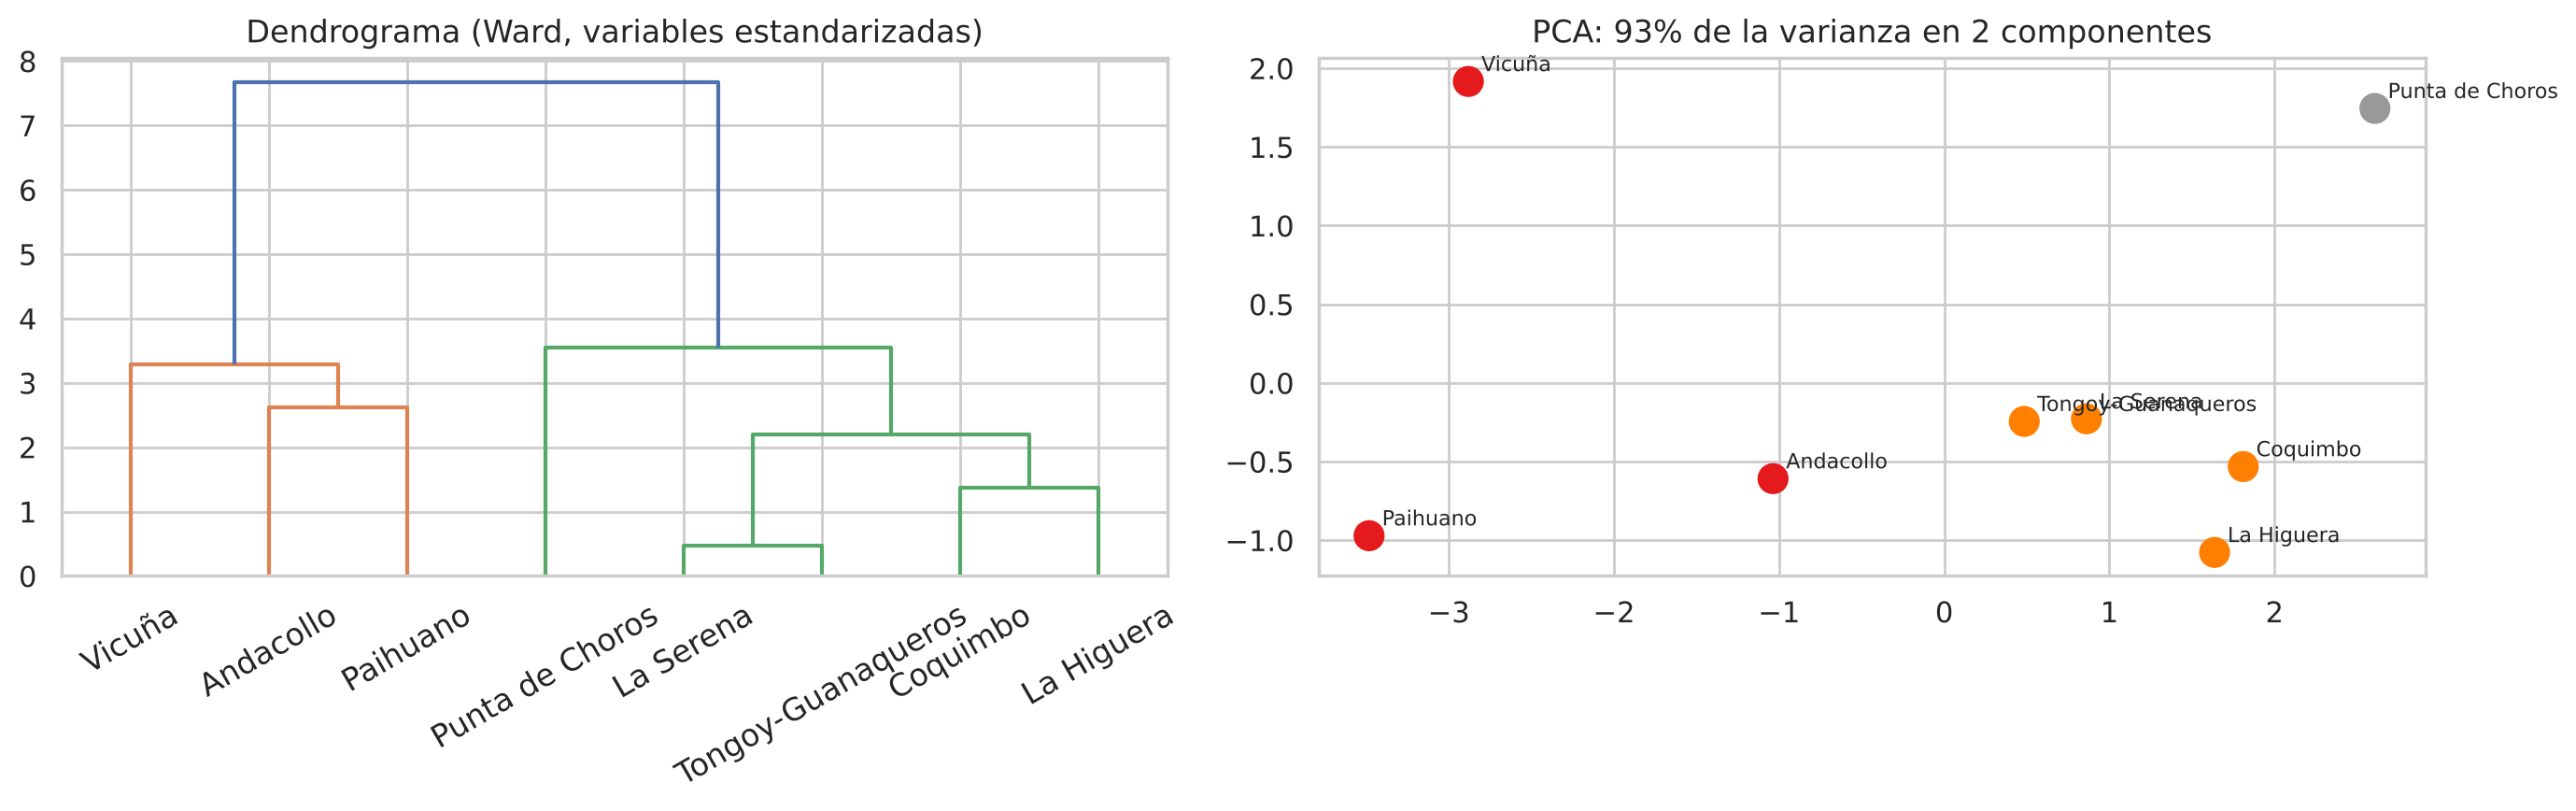

,t_media,t_verano,t_invierno,amplitud,radiacion,humedad,grupo
localidad,,,,,,,
Andacollo,16.2,24.5,8.3,9.3,22.2,57.8,1
Coquimbo,14.3,21.0,8.0,7.2,20.2,81.6,2
La Higuera,13.4,19.4,8.0,6.8,21.6,74.9,2
La Serena,15.0,22.8,8.3,8.6,20.5,78.2,2
Paihuano (Gabriela Mistral),19.7,28.5,7.8,10.4,23.3,40.8,1
Punta de Choros,14.6,20.5,10.0,5.3,19.1,82.5,3
Tongoy-Guanaqueros,15.2,23.2,8.3,9.2,20.5,74.2,2
Vicuña,19.2,29.1,10.5,10.6,22.2,53.0,1


In [9]:
feats = df.groupby("localidad").agg(t_media=("tmean", "mean"), t_verano=("tmax", lambda s: s[df.loc[s.index, "mes"].isin([12, 1, 2])].mean()),
                                    t_invierno=("tmin", lambda s: s[df.loc[s.index, "mes"].isin([6, 7, 8])].mean()),
                                    amplitud=("amplitud", "mean"), radiacion=("radiacion_MJm2", "mean"),
                                    humedad=("hr_media", "mean"))
Z = StandardScaler().fit_transform(feats)
link = linkage(Z, "ward")
feats["grupo"] = fcluster(link, 3, "maxclust")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dendrogram(link, labels=[l.split(" (")[0] for l in feats.index], ax=axes[0], leaf_rotation=30)
axes[0].set_title("Dendrograma (Ward, variables estandarizadas)")
pc = PCA(2).fit(Z); P = pc.transform(Z)
axes[1].scatter(P[:, 0], P[:, 1], c=feats.grupo, cmap="Set1", s=120)
for (x, y), loc in zip(P, feats.index):
    axes[1].annotate(loc.split(" (")[0], (x, y), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[1].set_title(f"PCA: {pc.explained_variance_ratio_.sum():.0%} de la varianza en 2 componentes")
plt.tight_layout(); plt.savefig(FIG / "clusters.png", dpi=120); plt.show()
feats.round(1)

## 7. Dashboard interactivo

Se exporta un HTML autocontenido (Plotly) con la serie diaria de cada localidad, para abrir en el navegador.

In [10]:
import plotly.express as px
fig = px.line(df, x="fecha", y="tmean", color="localidad",
              hover_data={"tmax": True, "tmin": True, "precip_mm": True},
              title="Temperatura media diaria – Región de Coquimbo (Open-Meteo)",
              labels={"tmean": "°C", "fecha": ""})
fig.update_layout(template="plotly_white", height=500, legend_title_text="")
fig.write_html("../figures/dashboard_temperaturas.html", include_plotlyjs="cdn")
print("Guardado figures/dashboard_temperaturas.html")

Guardado figures/dashboard_temperaturas.html


## 8. Comparación con el laboratorio original (OpenWeather, ene–ago 2025)

In [11]:
ene_ago = df[(df.anio == 2025) & (df.mes <= 8)]
comp = ene_ago.groupby("localidad").tmean.mean().round(2).sort_values()
comp

localidad
La Higuera                     13.45
Coquimbo                       14.20
Punta de Choros                14.69
Tongoy-Guanaqueros             14.79
La Serena                      14.83
Andacollo                      15.94
Paihuano (Gabriela Mistral)    19.04
Vicuña                         19.09
Name: tmean, dtype: float64

## Conclusiones
- El clustering separa **tres grupos**: (1) interior cálido y seco —Vicuña, Paihuano y Andacollo— con 16–20 °C de
  media, veranos sobre 24 °C, humedad de 40–58 % y la mayor amplitud térmica (9–11 °C); (2) la costa templada
  —Coquimbo, La Serena, Tongoy y La Higuera, esta última por la neblina costera— con 13–15 °C y humedad sobre 74 %;
  y (3) **Punta de Choros**, la costa más estable: la menor amplitud (5,3 °C) y los inviernos más templados (10 °C de
  mínima media), lo mismo que el laboratorio original identificó como "clima anómalo".
- La amplitud térmica crece con la elevación y la distancia al mar: la camanchaca modera la costa, mientras que en
  el valle de Elqui el día es cálido y la noche fría.
- La lluvia se concentra en 12–18 días al año y en pocos frentes de invierno que alcanzan a toda la región el mismo
  día (13–14 de junio y 2 de agosto de 2024, 1 de agosto de 2025).
- Diferencia con el laboratorio original (OpenWeather, ene–ago 2025): ahí Punta de Choros salía como la más cálida
  en promedio; con Open-Meteo lo son Vicuña y Paihuano. Open-Meteo usa reanálisis en una grilla de ~10 km, por lo
  que los puntos costeros incluyen parte del océano; para un estudio fino conviene contrastar con las estaciones de
  CEAZA.